# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

In [1]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
# like the tutorial make part 1 modules importable
import sys
from pathlib import Path
 
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1
from part1 import clslib, experiment, loglin, smlp, analysis, utils, bpe

In [3]:
import numpy as np

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

# The order below fixes our integer<->name mapping for the whole project which is our deliberate choice
snli_outcome_space = clslib.NamedClasses(['entailment', 'neutral', 'contradiction'])
print(snli_outcome_space)

0: entailment, 1: neutral, 2: contradiction


### **Load Dataset**

In [4]:
from datasets import load_dataset

snli = load_dataset("stanfordnlp/snli")
print(snli)

README.md:   0%|          | 0.00/16.0k [00:00<?, ?B/s]

c:\Users\Uzivatel\Desktop\UvA\1 Semester\Period 2\Natural Language Processing 1\Week 1\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Uzivatel\.cache\huggingface\hub\datasets--stanfordnlp--snli. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Uzivatel\Desktop\

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  412kB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  413kB            

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/550152 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 550152
    })
})


In [9]:
snli["train"][0]

{'premise': 'A person on a horse jumps over a broken down airplane.',
 'hypothesis': 'A person is training his horse for a competition.',
 'label': 1}

In [21]:
train = snli["train"]
val = snli["validation"]
test = snli["test"]

In [15]:
df = train.to_pandas() if hasattr(train, "to_pandas") else train

In [19]:
df.describe(include="all")  # unique premise: only 150736

,premise,hypothesis,label
count,550152,550152,550152.000000
unique,150736,480042,NaN
top,A dog in a field.,A man is sleeping.,NaN
freq,33,335,NaN
mean,NaN,NaN,0.996730
std,NaN,NaN,0.819796
min,NaN,NaN,-1.000000
25%,NaN,NaN,0.000000
50%,NaN,NaN,1.000000
75%,NaN,NaN,2.000000


In [28]:
identical_entailments = snli["train"].filter(
    lambda ex: ex["label"] == 0 and ex["premise"] == ex["hypothesis"]
)

neutral_identical_entailments = snli["train"].filter(
    lambda ex: ex["label"] == 1 and ex["premise"] == ex["hypothesis"]
)

contradiction_identical_entailments = snli["train"].filter(
    lambda ex: ex["label"] == 2 and ex["premise"] == ex["hypothesis"]
)


print(len(identical_entailments))
print(len(neutral_identical_entailments))
print(len(contradiction_identical_entailments))


267
25
17


In [22]:
print(f"original train: {len(train)}")

original train: 550152


In [32]:
train_after_first_dropping = train.filter(
    lambda sample: sample["label"] != -1
)
print(f"Train pairs after dropping -1: {len(train_after_first_dropping)}")

Filter:   0%|          | 0/550152 [00:00<?, ? examples/s]

Train pairs after dropping -1: 549367


In [33]:
train_after_second_dropping = train_after_first_dropping.filter(
    lambda sample: not (
        sample["premise"] == sample["hypothesis"]
        and sample["label"] in (1, 2)
    )
)

print(f"Train pairs after dropping -1: {len(train_after_second_dropping)}")

Filter:   0%|          | 0/549367 [00:00<?, ? examples/s]

Train pairs after dropping -1: 549325


## **Subsampling**

- subsampling using hugging face methods

In [36]:
from sklearn.model_selection import train_test_split

WORKING_SET_SIZE = 40_000
SUBSAMPLE_SEED = 0

In [38]:
splits = train_after_second_dropping.train_test_split(
    train_size=WORKING_SET_SIZE,
    seed=SUBSAMPLE_SEED,
    stratify_by_column="label"
)

work_split = splits["train"]
test_split = splits["test"]

X_work = list(zip(work_split["premise"], work_split["hypothesis"]))
y_work = work_split["label"]


In [39]:
working_set = list(zip(X_work, y_work))

In [40]:
from collections import Counter
print(f"Working set size: {len(working_set)}")
print("Label dist (0/1/2):", dict(sorted(Counter(y_work).items())))

Working set size: 40000
Label dist (0/1/2): {0: 13356, 1: 13306, 2: 13338}


In [99]:
vocab_size = 2_000
min_frequency = 2

In [100]:
corpus = list(work_split["premise"]) + list(work_split["hypothesis"])
tokenizer = part1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)

In [50]:
class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")
        

## **Cross-Validation Sets**

In [85]:
%%time
my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(X_work, y_work)), 
            k=num_folds,
            seed=seed
        )
    )

CPU times: total: 891 ms
Wall time: 897 ms


In [68]:
results_folder = "project_results"

In [125]:
import re
from collections import Counter

from scipy.sparse import hstack
from sklearn.feature_extraction import FeatureHasher


class PairWordUnigramBigramCounts:
    """
    Word-level count encoder for (premise, hypothesis) pairs.

    Output blocks:
        premise unigrams
        premise bigrams
        hypothesis unigrams
        hypothesis bigrams
    """

    def __init__(self, n_features_per_type=2**13, binary=False):
        self.n_features_per_type = n_features_per_type
        self.binary = binary

        self.unigram_hasher = FeatureHasher(
            n_features=n_features_per_type,
            input_type="dict",
            alternate_sign=False,
        )
        self.bigram_hasher = FeatureHasher(
            n_features=n_features_per_type,
            input_type="dict",
            alternate_sign=False,
        )


    @staticmethod
    def _words(text):
        return re.findall(r"(?u)[^\W_]+(?:['’][^\W_]+)*", text.lower())

    def _counts(self, text, ngram_size):
        words = self._words(text)

        if ngram_size == 1:
            counts = Counter(words)
        else:
            bigrams = (
                f"{left}\x1f{right}"
                for left, right in zip(words, words[1:])
            )
            counts = Counter(bigrams)

        return dict(counts)

    def _encode(self, hasher, counts):
        vector = hasher.transform([counts]).tocsr()

        if self.binary:
            # Mark each active hashed feature once instead of counting it.
            vector.data[:] = 1.0

        return vector.astype("float32")

    def __call__(self, pair):
        if not isinstance(pair, (tuple, list)) or len(pair) != 2:
            raise ValueError(
                "Expected a pair: (premise, hypothesis), containing two strings."
            )

        premise, hypothesis = pair

        p_unigrams = self._encode(
            self.unigram_hasher, self._counts(premise, 1)
        )
        p_bigrams = self._encode(
            self.bigram_hasher, self._counts(premise, 2)
        )
        h_unigrams = self._encode(
            self.unigram_hasher, self._counts(hypothesis, 1)
        )
        h_bigrams = self._encode(
            self.bigram_hasher, self._counts(hypothesis, 2)
        )

        return hstack(
            [p_unigrams, p_bigrams, h_unigrams, h_bigrams],
            format="csr",
        ).astype("float32")

    def __len__(self):
        return 4 * self.n_features_per_type

In [126]:
word_ngram_encoder = PairWordUnigramBigramCounts(
    n_features_per_type=2**13,
    binary=False,  # counts; set True for presence indicators
)

In [128]:
sample_pair = working_set[0][0]  # expects (premise, hypothesis)
sample_vector = word_ngram_encoder(sample_pair)

print("Shape:", sample_vector.shape)
print("Non-zero features:", sample_vector.nnz)

Shape: (1, 32768)
Non-zero features: 32


## **(BPE) Token Indicators**

In [ ]:
from tokenizers import Tokenizer

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

In [57]:
class PairTokenIndicators(Encoder):
    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self) -> int:
        return 2 * self.vocab_size

    def _indicators(self, text):
        token_ids = self.tokenizer.encode(text).ids
        vector = np.zeros(self.vocab_size, dtype=np.float32)
        vector[token_ids] = 1.0
        return vector

    def __call__(self, x) -> np.ndarray:
        premise, hypothesis = x
        return np.concatenate([
            self._indicators(premise),
            self._indicators(hypothesis)
        ])

In [101]:
encoder = PairTokenIndicators(tokenizer)

example_vector = encoder(X_work[0])
print("Vector shape:", example_vector.shape)
print("Expected shape:", len(encoder))
print("Active indicators:", int(example_vector.sum()))

Vector shape: (4000,)
Expected shape: 4000
Active indicators: 25


In [105]:
from sklearn.metrics import accuracy_score

first_fold = my_cross_validation_sets[0][0]

logistic_model = part1.loglin.fit(
    first_fold["training"],
    token_indicator_encoder,
    save_to=None
)

validation = first_fold["validation"]
X_valid = [x for x, label in validation]
y_valid = [label for x, label in validation]

predictions = part1.loglin.predict(
    X_valid,
    logistic_model,
    token_indicator_encoder
)

print("Accuracy:", accuracy_score(y_valid, predictions))

KeyboardInterrupt: 

In [ ]:
from collections import OrderedDict

my_classifiers = OrderedDict()
my_classifiers["logistic_indicator-enc"] = []

for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_indicator-enc-vs2K/seed-{seed}"

    my_classifiers["logistic_indicator-enc"].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=snli_outcome_space,
            encoder=token_indicator_encoder,
            model_option="logistic",
            save_to=run_folder,
            loglin_args={"max_iter": 300}
        )
    )

results_df = part1.analysis.make_data_frame(my_classifiers)
print(results_df.to_string(index=False))

  0%|          | 0/5 [00:00<?, ?it/s]

                 model  accuracy  run  fold
logistic_indicator-enc  0.568125    0     0
logistic_indicator-enc  0.570125    0     1
logistic_indicator-enc  0.570375    0     2
logistic_indicator-enc  0.574750    0     3
logistic_indicator-enc  0.575750    0     4


In [106]:
my_classifiers = OrderedDict()

In [107]:
vocab_size = 2_000
min_frequency = 2

In [108]:
corpus = list(work_split["premise"]) + list(work_split["hypothesis"])
tokenizer = part1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)

In [109]:
token_indicator_encoder = PairTokenIndicators(tokenizer)
pairs = list(zip(X_work, y_work))   

In [ ]:
def run_classifier(name, my_classifiers, encoder, model_option, max_iter, seeds = [0], results_folder = "results"):
    my_classifiers[name] = []

    for run, seed in enumerate(seeds):
        run_folder = f"{results_folder}/{name}/seed-{seed}"

        my_classifiers[name].append(
            part1.experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=snli_outcome_space,
                encoder=encoder,
                model_option=model_option,
                save_to=run_folder,
                loglin_args={"max_iter": max_iter}
            )
        )

    results_df = part1.analysis.make_data_frame(my_classifiers)
    print(results_df.to_string(index=False))

    return my_classifiers


In [110]:
my_classifiers = run_classifier(name = "logistic_indicator-enc", my_classifiers=my_classifiers, encoder = token_indicator_encoder, model_option = "logistic", max_iter = 300, seeds = [0], results_folder = "results")

  0%|          | 0/5 [00:00<?, ?it/s]

                 model  accuracy  run  fold
logistic_indicator-enc  0.577500    0     0
logistic_indicator-enc  0.572875    0     1
logistic_indicator-enc  0.573750    0     2
logistic_indicator-enc  0.581875    0     3
logistic_indicator-enc  0.586250    0     4


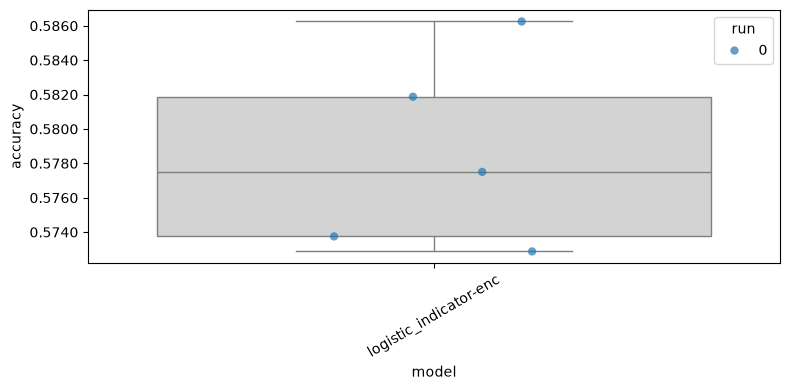

In [111]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

## **Bag Of Words**

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from scipy.sparse import hstack

In [ ]:
class BagOfWords(Encoder):
    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self) -> int:
        return self.vocab_size

    def __call__(self, x: str) -> np.ndarray:
        token_ids = self.tokenizer.encode(x).ids
        return np.bincount(
            token_ids,
            minlength=self.vocab_size
        ).astype(np.float32)

In [ ]:
bow_encoder = BagOfWords(tokenizer)
vector = bow_encoder("A short example sentence.")

print("Vector shape:", vector.shape)
print("Encoder dimension:", len(bow_encoder))
print("Total token counts:", vector.sum())

Vector shape: (2000,)
Encoder dimension: 2000
Total token counts: 9.0


In [ ]:
class PairBagOfWords(Encoder):
    def __init__(self, tokenizer, binary=False):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()
        self.binary = binary

    def __len__(self):
        # One vocabulary-sized block for the premise,
        # and one for the hypothesis.
        return 2 * self.vocab_size

    def _encode_sentence(self, sentence):
        token_ids = self.tokenizer.encode(sentence).ids
        counts = np.bincount(token_ids, minlength=self.vocab_size)

        if self.binary:
            counts = (counts > 0).astype(np.float32)
        else:
            counts = counts.astype(np.float32)

        return counts

    def __call__(self, pair):
        premise, hypothesis = pair

        premise_vector = self._encode_sentence(premise)
        hypothesis_vector = self._encode_sentence(hypothesis)

        return np.concatenate([premise_vector, hypothesis_vector])

In [112]:
pair_bow_encoder = PairBagOfWords(tokenizer, binary=False) 

In [ ]:
my_classifiers = run_classifier(name = "logistic_bow-enc", my_classifiers=my_classifiers, encoder = pair_bow_encoder, model_option = "logistic", max_iter = 400, seeds = [0], results_folder = "results") # 300 still gives warnings about convergence, 400 is okay

  0%|          | 0/5 [00:00<?, ?it/s]

                 model  accuracy  run  fold
logistic_indicator-enc  0.577500    0     0
logistic_indicator-enc  0.572875    0     1
logistic_indicator-enc  0.573750    0     2
logistic_indicator-enc  0.581875    0     3
logistic_indicator-enc  0.586250    0     4
      logistic_bow-enc  0.575875    0     0
      logistic_bow-enc  0.574250    0     1
      logistic_bow-enc  0.573375    0     2
      logistic_bow-enc  0.579250    0     3
      logistic_bow-enc  0.586000    0     4


In [ ]:
word_ngram_encoder

In [133]:
my_classifiers = run_classifier(name = "logistic_n_gram-enc", my_classifiers=my_classifiers, encoder = word_ngram_encoder, model_option = "logistic", max_iter = 1000, seeds = [0], results_folder = "results")

  0%|          | 0/5 [00:00<?, ?it/s]

                 model  accuracy  run  fold
logistic_indicator-enc  0.577500    0     0
logistic_indicator-enc  0.572875    0     1
logistic_indicator-enc  0.573750    0     2
logistic_indicator-enc  0.581875    0     3
logistic_indicator-enc  0.586250    0     4
      logistic_bow-enc  0.575875    0     0
      logistic_bow-enc  0.574250    0     1
      logistic_bow-enc  0.573375    0     2
      logistic_bow-enc  0.579250    0     3
      logistic_bow-enc  0.586000    0     4
     mlp_indicator-enc  0.576750    0     0
     mlp_indicator-enc  0.577125    0     1
     mlp_indicator-enc  0.580375    0     2
     mlp_indicator-enc  0.585250    0     3
     mlp_indicator-enc  0.592250    0     4
           mlp_bow-enc  0.576625    0     0
           mlp_bow-enc  0.579000    0     1
           mlp_bow-enc  0.577750    0     2
           mlp_bow-enc  0.584875    0     3
           mlp_bow-enc  0.592000    0     4
   logistic_n_gram-enc  0.540250    0     0
   logistic_n_gram-enc  0.534500

In [ ]:

my_classifiers["logistic_bow-enc"] = []

for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc-vs4K/seed-{seed}"

    my_classifiers["logistic_bow-enc"].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=snli_outcome_space,
            encoder=pair_bow_encoder,
            model_option="logistic",
            save_to=run_folder,
            loglin_args={"max_iter": 300}
        )
    )

results_df = part1.analysis.make_data_frame(my_classifiers)
print(results_df.to_string(index=False))

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\Uzivatel\Desktop\UvA\1 Semester\Period 2\Natural Language Processing 1\Week 1\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\Uzivatel\Desktop\UvA\1 Semester\Period 2\Natural Language Processing 1\Week 1\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\Uzivatel\Desktop\UvA\1 Semester\Period 2\Natural Language Processing 1\Week 1\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\Uzivatel\Desktop\UvA\1 Semester\Period 2\Natural Language Processing 1\Week 1\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: Conve

                 model  accuracy  run  fold
logistic_indicator-enc  0.564500    0     0
logistic_indicator-enc  0.575500    0     1
logistic_indicator-enc  0.564625    0     2
logistic_indicator-enc  0.573000    0     3
logistic_indicator-enc  0.576000    0     4
      logistic_bow-enc  0.565625    0     0
      logistic_bow-enc  0.573250    0     1
      logistic_bow-enc  0.565625    0     2
      logistic_bow-enc  0.572000    0     3
      logistic_bow-enc  0.576375    0     4


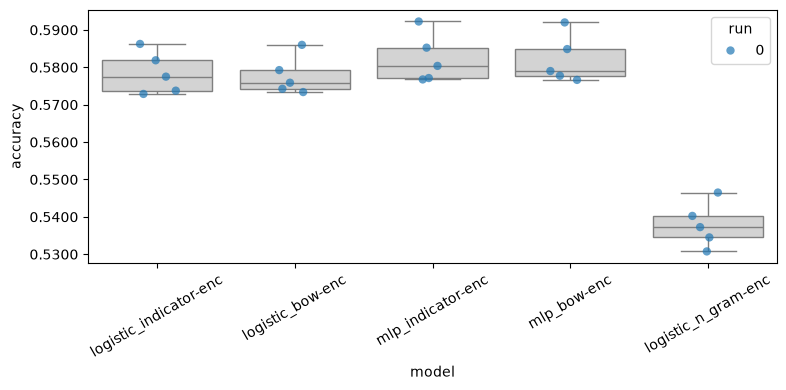

In [134]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

In [120]:
my_classifiers["logistic_bow-enc"]

[{'models': OrderedDict([(0,
                'results\\logistic_bow-enc\\seed-0\\fold-0/model'),
               (1, 'results\\logistic_bow-enc\\seed-0\\fold-1/model'),
               (2, 'results\\logistic_bow-enc\\seed-0\\fold-2/model'),
               (3, 'results\\logistic_bow-enc\\seed-0\\fold-3/model'),
               (4, 'results\\logistic_bow-enc\\seed-0\\fold-4/model')]),
  'predictions': OrderedDict([(0,
                array([0, 2, 0, ..., 2, 1, 1], shape=(8000,))),
               (1, array([0, 1, 1, ..., 1, 0, 1], shape=(8000,))),
               (2, array([2, 2, 0, ..., 0, 2, 1], shape=(8000,))),
               (3, array([1, 1, 1, ..., 0, 0, 0], shape=(8000,))),
               (4, array([2, 2, 0, ..., 1, 2, 1], shape=(8000,)))]),
  'accuracies': OrderedDict([(0, 0.575875),
               (1, 0.57425),
               (2, 0.573375),
               (3, 0.57925),
               (4, 0.586)])}]

In [122]:
import pandas as pd
from sklearn.metrics import confusion_matrix

In [123]:
model_key = "mlp_indicator-enc"  # change to your logistic-regression key if needed
run_idx = 0                      # first seed/run

run_result = my_classifiers[model_key][run_idx]
folds = my_cross_validation_sets[run_idx]

y_true, y_pred = [], []

for fold, fold_predictions in run_result["predictions"].items():
    validation_set = folds[fold]["validation"]

    y_true.extend(label for text, label in validation_set)
    y_pred.extend(np.asarray(fold_predictions).tolist())

# Use the same label order for both axes
labels = sorted(set(y_true) | set(y_pred))

cm = confusion_matrix(y_true, y_pred, labels=labels)
cm_df = pd.DataFrame(
    cm,
    index=pd.Index(labels, name="True label"),
    columns=pd.Index(labels, name="Predicted label"),
)
print(cm_df)

# Per-class error rates: higher means that true label is more often misclassified
cm_normalized = confusion_matrix(
    y_true, y_pred, labels=labels, normalize="true"
)
error_rates = pd.Series(
    1 - np.diag(cm_normalized), index=labels, name="Error rate"
).sort_values(ascending=False)

print("\nPer-class error rates:")
print(error_rates)

Predicted label     0     1     2
True label                       
0                8589  2193  2574
1                2938  7444  2924
2                3093  2984  7261

Per-class error rates:
2    0.455616
1    0.440553
0    0.356918
Name: Error rate, dtype: float64


## **MLP**

In [116]:
%%time
my_classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    my_classifiers['mlp_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=snli_outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-4, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
            }
        )
    )

results_df = part1.analysis.make_data_frame(my_classifiers)
print(results_df.to_string(index=False))

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.102 seconds
Dataloader done! Time taken: 1.130 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\Uzivatel\Desktop\UvA\1 Semester\Period 2\Natural Language Processing 1\Week 1\nlp1-student-tutorial1-2026\part1\smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:255.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
c:\Users\Uzivatel\Desktop\UvA\1 Semester\Period 2\Natural Language Processing 1\Week 1\nlp1-student-tutorial1-2026\part1\smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\

Epoch 01 | train loss: 1.0805 | train acc: 0.4325 | val loss: 1.0513 | val acc: 0.5129
Epoch 02 | train loss: 1.0001 | train acc: 0.5526 | val loss: 0.9803 | val acc: 0.5409
Epoch 03 | train loss: 0.9218 | train acc: 0.5947 | val loss: 0.9453 | val acc: 0.5584
Epoch 04 | train loss: 0.8680 | train acc: 0.6232 | val loss: 0.9252 | val acc: 0.5686
Epoch 05 | train loss: 0.8301 | train acc: 0.6405 | val loss: 0.9170 | val acc: 0.5717
Epoch 06 | train loss: 0.8018 | train acc: 0.6543 | val loss: 0.9128 | val acc: 0.5767
Epoch 07 | train loss: 0.7789 | train acc: 0.6656 | val loss: 0.9130 | val acc: 0.5796
Epoch 08 | train loss: 0.7610 | train acc: 0.6731 | val loss: 0.9143 | val acc: 0.5779
Epoch 09 | train loss: 0.7457 | train acc: 0.6809 | val loss: 0.9171 | val acc: 0.5809
Epoch 10 | train loss: 0.7306 | train acc: 0.6878 | val loss: 0.9202 | val acc: 0.5809
Training done! Time taken: 76.440 seconds
Transforming documents...
Document transformation done! Time taken: 2.021 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0814 | train acc: 0.4357 | val loss: 1.0533 | val acc: 0.5259
Epoch 02 | train loss: 1.0014 | train acc: 0.5551 | val loss: 0.9779 | val acc: 0.5574
Epoch 03 | train loss: 0.9214 | train acc: 0.5959 | val loss: 0.9375 | val acc: 0.5714
Epoch 04 | train loss: 0.8690 | train acc: 0.6220 | val loss: 0.9178 | val acc: 0.5791
Epoch 05 | train loss: 0.8309 | train acc: 0.6392 | val loss: 0.9059 | val acc: 0.5837
Epoch 06 | train loss: 0.8031 | train acc: 0.6534 | val loss: 0.9022 | val acc: 0.5871
Epoch 07 | train loss: 0.7800 | train acc: 0.6656 | val loss: 0.9006 | val acc: 0.5853
Epoch 08 | train loss: 0.7612 | train acc: 0.6741 | val loss: 0.9020 | val acc: 0.5885
Epoch 09 | train loss: 0.7452 | train acc: 0.6830 | val loss: 0.9051 | val acc: 0.5885
Epoch 10 | train loss: 0.7305 | train acc: 0.6884 | val loss: 0.9084 | val acc: 0.5880
Training done! Time taken: 52.609 seconds
Transforming documents...
Document transformation done! Time taken: 2.005 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0805 | train acc: 0.4419 | val loss: 1.0507 | val acc: 0.5164
Epoch 02 | train loss: 1.0023 | train acc: 0.5508 | val loss: 0.9761 | val acc: 0.5550
Epoch 03 | train loss: 0.9248 | train acc: 0.5901 | val loss: 0.9346 | val acc: 0.5735
Epoch 04 | train loss: 0.8728 | train acc: 0.6182 | val loss: 0.9120 | val acc: 0.5830
Epoch 05 | train loss: 0.8339 | train acc: 0.6374 | val loss: 0.9015 | val acc: 0.5885
Epoch 06 | train loss: 0.8052 | train acc: 0.6524 | val loss: 0.8957 | val acc: 0.5879
Epoch 07 | train loss: 0.7819 | train acc: 0.6618 | val loss: 0.8938 | val acc: 0.5923
Epoch 08 | train loss: 0.7632 | train acc: 0.6716 | val loss: 0.8945 | val acc: 0.5921
Epoch 09 | train loss: 0.7472 | train acc: 0.6777 | val loss: 0.8955 | val acc: 0.5925
Epoch 10 | train loss: 0.7312 | train acc: 0.6865 | val loss: 0.8988 | val acc: 0.5929
Training done! Time taken: 74.620 seconds
                 model  accuracy  run  fold
logistic_indicator-enc  0.577500    0     0


In [118]:
%%time
my_classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    my_classifiers['mlp_bow-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=snli_outcome_space,
            encoder=pair_bow_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-4, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
            }
        )
    )

results_df = part1.analysis.make_data_frame(my_classifiers)
print(results_df.to_string(index=False))

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 3.529 seconds
Dataloader done! Time taken: 2.520 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0814 | train acc: 0.4316 | val loss: 1.0536 | val acc: 0.5169
Epoch 02 | train loss: 1.0035 | train acc: 0.5538 | val loss: 0.9848 | val acc: 0.5455
Epoch 03 | train loss: 0.9249 | train acc: 0.5965 | val loss: 0.9472 | val acc: 0.5615
Epoch 04 | train loss: 0.8708 | train acc: 0.6231 | val loss: 0.9279 | val acc: 0.5650
Epoch 05 | train loss: 0.8324 | train acc: 0.6416 | val loss: 0.9194 | val acc: 0.5726
Epoch 06 | train loss: 0.8030 | train acc: 0.6559 | val loss: 0.9154 | val acc: 0.5766
Epoch 07 | train loss: 0.7793 | train acc: 0.6668 | val loss: 0.9146 | val acc: 0.5766
Epoch 08 | train loss: 0.7602 | train acc: 0.6761 | val loss: 0.9158 | val acc: 0.5790
Epoch 09 | train loss: 0.7427 | train acc: 0.6834 | val loss: 0.9195 | val acc: 0.5799
Epoch 10 | train loss: 0.7273 | train acc: 0.6905 | val loss: 0.9213 | val acc: 0.5825
Training done! Time taken: 56.474 seconds
Transforming documents...
Document transformation done! Time taken: 2.215 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0792 | train acc: 0.4487 | val loss: 1.0520 | val acc: 0.5159
Epoch 02 | train loss: 1.0005 | train acc: 0.5548 | val loss: 0.9842 | val acc: 0.5389
Epoch 03 | train loss: 0.9241 | train acc: 0.5958 | val loss: 0.9469 | val acc: 0.5644
Epoch 04 | train loss: 0.8708 | train acc: 0.6239 | val loss: 0.9269 | val acc: 0.5730
Epoch 05 | train loss: 0.8324 | train acc: 0.6419 | val loss: 0.9170 | val acc: 0.5743
Epoch 06 | train loss: 0.8038 | train acc: 0.6560 | val loss: 0.9122 | val acc: 0.5784
Epoch 07 | train loss: 0.7807 | train acc: 0.6649 | val loss: 0.9106 | val acc: 0.5790
Epoch 08 | train loss: 0.7618 | train acc: 0.6735 | val loss: 0.9111 | val acc: 0.5817
Epoch 09 | train loss: 0.7451 | train acc: 0.6815 | val loss: 0.9150 | val acc: 0.5823
Epoch 10 | train loss: 0.7301 | train acc: 0.6911 | val loss: 0.9167 | val acc: 0.5814
Training done! Time taken: 96.471 seconds
Transforming documents...
Document transformation done! Time taken: 4.748 seconds
Datalo

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0812 | train acc: 0.4384 | val loss: 1.0542 | val acc: 0.5165
Epoch 02 | train loss: 1.0037 | train acc: 0.5575 | val loss: 0.9812 | val acc: 0.5480
Epoch 03 | train loss: 0.9247 | train acc: 0.5948 | val loss: 0.9400 | val acc: 0.5697
Epoch 04 | train loss: 0.8712 | train acc: 0.6232 | val loss: 0.9191 | val acc: 0.5791
Epoch 05 | train loss: 0.8326 | train acc: 0.6411 | val loss: 0.9082 | val acc: 0.5823
Epoch 06 | train loss: 0.8032 | train acc: 0.6567 | val loss: 0.9044 | val acc: 0.5853
Epoch 07 | train loss: 0.7791 | train acc: 0.6682 | val loss: 0.9033 | val acc: 0.5849
Epoch 08 | train loss: 0.7583 | train acc: 0.6761 | val loss: 0.9046 | val acc: 0.5849
Epoch 09 | train loss: 0.7417 | train acc: 0.6841 | val loss: 0.9064 | val acc: 0.5874
Epoch 10 | train loss: 0.7260 | train acc: 0.6930 | val loss: 0.9100 | val acc: 0.5863
Training done! Time taken: 97.548 seconds
Transforming documents...
Document transformation done! Time taken: 1.853 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0826 | train acc: 0.4257 | val loss: 1.0555 | val acc: 0.5171
Epoch 02 | train loss: 1.0070 | train acc: 0.5543 | val loss: 0.9809 | val acc: 0.5535
Epoch 03 | train loss: 0.9290 | train acc: 0.5908 | val loss: 0.9363 | val acc: 0.5784
Epoch 04 | train loss: 0.8749 | train acc: 0.6173 | val loss: 0.9140 | val acc: 0.5847
Epoch 05 | train loss: 0.8360 | train acc: 0.6374 | val loss: 0.9022 | val acc: 0.5861
Epoch 06 | train loss: 0.8069 | train acc: 0.6510 | val loss: 0.8975 | val acc: 0.5884
Epoch 07 | train loss: 0.7850 | train acc: 0.6617 | val loss: 0.8950 | val acc: 0.5895
Epoch 08 | train loss: 0.7663 | train acc: 0.6707 | val loss: 0.8950 | val acc: 0.5920
Epoch 09 | train loss: 0.7497 | train acc: 0.6799 | val loss: 0.8973 | val acc: 0.5927
Epoch 10 | train loss: 0.7343 | train acc: 0.6849 | val loss: 0.8997 | val acc: 0.5923
Training done! Time taken: 47.084 seconds
                 model  accuracy  run  fold
logistic_indicator-enc  0.577500    0     0


In [ ]:
logistic_n_gram-enc

In [136]:
%%time
my_classifiers['mlp_n_gram-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_n_gram-enc/seed-{seed}"
    my_classifiers['mlp_n_gram-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=snli_outcome_space,
            encoder=word_ngram_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-4, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
            }
        )
    )

results_df = part1.analysis.make_data_frame(my_classifiers)
print(results_df.to_string(index=False))

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 40.154 seconds
CPU times: total: 33.1 s
Wall time: 40.2 s


ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all().